In [1]:
# توسعه بازی Nim: انتخاب حرکت با بالاترین امتیاز (شبیه به امتیازدهی به فیلم‌ها)
# هدف: انتخاب حرکتی که بازیکن را به بردن نزدیک‌تر می‌کند.
def nim_best_move(heap_size):
    # یک سیستم امتیازدهی ساده: حرکت‌هایی که بُرد را تضمین می‌کنند امتیاز بالاتری دارند.
    # برای سادگی، اگر تعداد سنگ‌ها مضرب ۴ باشد (قانون نیم)، حرکت تصادفی، در غیر این صورت حرکت به مضرب ۴.
    best_move = heap_size % 4 if heap_size % 4 != 0 else 1
    return best_move

# نسخه اولیه (تصادفی) در مقابل نسخه توسعه‌یافته (هوشمند)
import random
def nim_original():
    return random.choice([1, 2, 3])

print("حرکت اولیه (تصادفی):", nim_original())
print("حرکت توسعه‌یافته (سیستم امتیازدهی):", nim_best_move(10))
print("ارتباط با پروژه: در سیستم پیشنهاد فیلم نیز، ما با استفاده از شباهت کسینوسی به فیلم‌ها امتیاز می‌دهیم و بالاترین‌ها را پیشنهاد می‌دهیم.")

حرکت اولیه (تصادفی): 1
حرکت توسعه‌یافته (سیستم امتیازدهی): 2
ارتباط با پروژه: در سیستم پیشنهاد فیلم نیز، ما با استفاده از شباهت کسینوسی به فیلم‌ها امتیاز می‌دهیم و بالاترین‌ها را پیشنهاد می‌دهیم.


In [2]:
import pandas as pd
import urllib.request
import zipfile
import os

# ۱. دانلود دیتاست MovieLens (نسخه کوچک)
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
urllib.request.urlretrieve(url, "ml-latest-small.zip")

with zipfile.ZipFile("ml-latest-small.zip", 'r') as zip_ref:
    zip_ref.extractall(".")
print("دیتاست با موفقیت دانلود و استخراج شد.")

# ۲. لود کردن داده‌ها
movies = pd.read_csv("ml-latest-small/movies.csv")
ratings = pd.read_csv("ml-latest-small/ratings.csv")

# ۳. پاک‌سازی داده‌ها (بررسی مقادیر گمشده و تکراری)
print("\n--- بررسی داده‌ها ---")
print("تعداد مقادیر گمشده در Movies:\n", movies.isnull().sum())
print("تعداد مقادیر گمشده در Ratings:\n", ratings.isnull().sum())
print("تعداد رکوردهای تکراری در Ratings:", ratings.duplicated().sum())
ratings = ratings.drop_duplicates() # حذف تکراری‌ها

# ۴. جدا کردن Test Set (۲۰٪ داده‌ها برای تست)
from sklearn.model_selection import train_test_split
train_ratings, test_ratings = train_test_split(ratings, test_size=0.2, random_state=42)
print(f"\nتعداد داده‌های Train: {len(train_ratings)}")
print(f"تعداد داده‌های Test: {len(test_ratings)}")
print("مجموعه تست به صورت مستقل جدا شد.")

دیتاست با موفقیت دانلود و استخراج شد.

--- بررسی داده‌ها ---
تعداد مقادیر گمشده در Movies:
 movieId    0
title      0
genres     0
dtype: int64
تعداد مقادیر گمشده در Ratings:
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
تعداد رکوردهای تکراری در Ratings: 0

تعداد داده‌های Train: 80668
تعداد داده‌های Test: 20168
مجموعه تست به صورت مستقل جدا شد.


--- آمار توصیفی امتیازات ---
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64


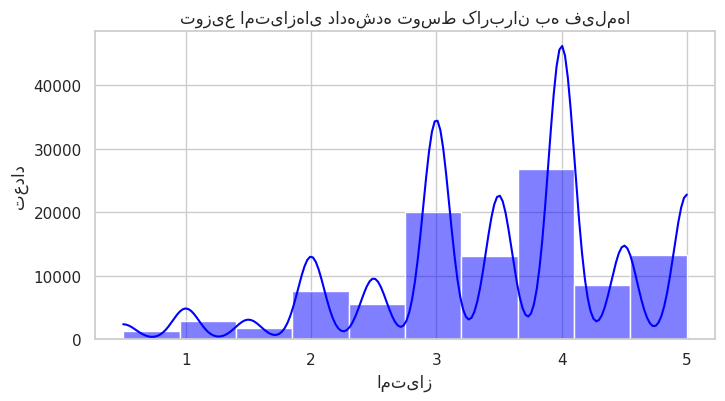

/tmp/ipykernel_585/2576292601.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ratings['movieId'].value_counts().head(10).values, y=top_movies_titles, palette='viridis')


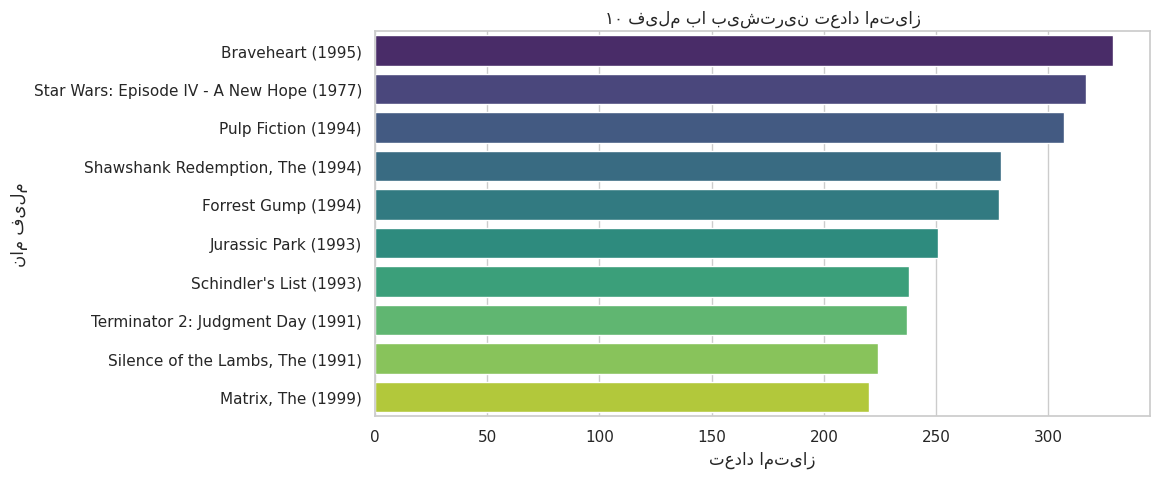

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# تنظیم استایل نمودارها
sns.set(style="whitegrid")

# ۱. آمار توصیفی داده‌ها
print("--- آمار توصیفی امتیازات ---")
print(ratings['rating'].describe())

# ۲. نمودار توزیع امتیازات (Histogram)
plt.figure(figsize=(8, 4))
sns.histplot(ratings['rating'], bins=10, kde=True, color='blue')
plt.title("توزیع امتیازهای داده‌شده توسط کاربران به فیلم‌ها")
plt.xlabel("امتیاز")
plt.ylabel("تعداد")
plt.show()

# ۳. نمودار ۱۰ فیلم برتر از نظر تعداد امتیاز
top_movies = ratings['movieId'].value_counts().head(10).index
top_movies_titles = movies[movies['movieId'].isin(top_movies)]['title'].tolist()

plt.figure(figsize=(10, 5))
sns.barplot(x=ratings['movieId'].value_counts().head(10).values, y=top_movies_titles, palette='viridis')
plt.title("۱۰ فیلم با بیشترین تعداد امتیاز")
plt.xlabel("تعداد امتیاز")
plt.ylabel("نام فیلم")
plt.show()